# Feature Engineering & Preprocessing Pipeline
### End-to-end, leak-free machine-learning project (Titanic survival classification)

**Goal:** build a reusable scikit-learn pipeline that imputes, clips outliers, scales, encodes and models the data, while making sure **no information from the test set ever leaks into training**.

**How this notebook is organised**

| # | Section | What you will learn |
|---|---------|--------------------|
| 0 | Setup | Libraries and reusable code from `preprocessing_pipeline.py` |
| 1 | Dataset | Why Titanic, source, loading, basic inspection, duplicates |
| 2 | Train/test split & data leakage | Why we split *first* and what leakage is |
| 3 | EDA | Missing values, distributions, outliers, correlations (training data only) |
| 4 | Feature engineering | New features, dropped features, high-cardinality handling |
| 5 | Preprocessing pipeline | `ColumnTransformer` + `Pipeline`, fitted on train only |
| 6 | Correlation & multicollinearity | Pearson, VIF, a *tested* decision about redundant features |
| 7 | Feature importance | Mutual Information vs Random Forest importance |
| 8 | Model & evaluation | Baseline model, metrics, confusion matrix, ROC |
| 9 | Final validation | Automated checks (leakage, NaNs, unseen categories, names ...) |
| 10 | Reusability demo | The same pipeline code on the uploaded `customer-churn-training.csv` |
| 11 | Summary & viva Q&A | Key findings, limitations, likely examiner questions |

## 0. Setup

We import the standard libraries and our own module `preprocessing_pipeline.py`. Keeping the reusable logic in a `.py` file (and only *calling* it from the notebook) is what makes the pipeline **reusable**: the same functions can be imported in a script, an API, or another notebook.

`RANDOM_STATE = 42` is used everywhere so the results are reproducible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import sklearn
from sklearn import set_config
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split

from preprocessing_pipeline import (
    RANDOM_STATE, TARGET_COL, TitanicFeatureEngineer,
    aggregate_by_original, build_pipeline, build_preprocessor,
    compute_mutual_information, evaluate_classifier, get_feature_map,
    iqr_outlier_report, load_data,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.labelsize": 11})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_summary(pipeline, X, y):
    """5-fold stratified CV on the given data. The WHOLE pipeline is re-fitted inside every fold,
    so imputers/scalers/encoders only ever see that fold's training part (no leakage)."""
    res = cross_validate(pipeline, X, y, cv=CV, scoring=["accuracy", "f1", "roc_auc"])
    return {m: (res[f"test_{m}"].mean(), res[f"test_{m}"].std()) for m in ["accuracy", "f1", "roc_auc"]}

def barh(series, title, xlabel, ylabel, ax=None, color="#2a6f97", fmt="{:.3f}"):
    """Readable horizontal bar chart with value labels."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 5))
    s = series.sort_values()
    ax.barh(s.index.astype(str), s.values, color=color)
    for y_pos, v in enumerate(s.values):
        ax.text(v, y_pos, " " + fmt.format(v), va="center", fontsize=9)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.set_xlim(0, s.max() * 1.15)
    return ax

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.4


## 1. Dataset selection and loading

**Chosen dataset: Titanic passenger data (891 passengers, 12 columns)** – a real historical dataset. Target = `Survived` (1 = survived, 0 = died), so this is **binary classification**.

**Why Titanic fits this project better than the other options:**
- It has **numerical** features (`Age`, `Fare`, `SibSp`, `Parch`, `Pclass`) → needed for scaling.
- It has **categorical** features (`Sex`, `Embarked`) and **text-like high-cardinality** features (`Name`, `Ticket`, `Cabin`) → needed for encoding and careful feature handling.
- It has **real missing values** (`Age`, `Cabin`, `Embarked`) → needed for imputation.
- It has a clear target and enough hidden structure for **feature engineering** (titles in names, family size, cabin deck).

**Source:** the public GitHub mirror `datasciencedojo/datasets/titanic.csv` of the well-known Kaggle *"Titanic – Machine Learning from Disaster"* training file. A copy is bundled at `data/titanic.csv` so the notebook runs even without internet; `load_data()` tries the local file first and the URL second.

**Honest limitations:** only 891 rows (so test metrics are noisy), a 1912 event (not representative of modern data), and the labels are not "predictable" with certainty. It is a learning dataset; the focus here is the *pipeline*, not record-breaking accuracy.

> **Note on the uploaded files:** `customer-churn-training.csv` has only 12 rows and no missing values, which cannot support stratified splitting, imputation, or meaningful feature-importance analysis. It is therefore used only for a small reusability demo in Section 10.

In [2]:
df_raw = load_data()
print(f"Shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
display(df_raw.head())

Shape: 891 rows x 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0000,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0000,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0000,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0000,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0000,0,0,373450,8.0500,NaN,S


In [3]:
# Column overview: type, number of distinct values, number of missing values
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(),
    "n_missing": df_raw.isna().sum(),
})
display(overview)

,dtype,n_unique,n_missing
PassengerId,int64,891,0
Survived,int64,2,0
Pclass,int64,3,0
Name,str,891,0
Sex,str,2,0
Age,float64,88,177
SibSp,int64,7,0
Parch,int64,7,0
Ticket,str,681,0
Fare,float64,248,0


In [4]:
# Statistical summary (describe) for numeric and for text/categorical columns
display(df_raw.describe().T)
display(df_raw.select_dtypes(exclude="number").describe().T)

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0000,446.0000,257.3538,1.0000,223.5000,446.0000,668.5000,891.0000
Survived,891.0000,0.3838,0.4866,0.0000,0.0000,0.0000,1.0000,1.0000
Pclass,891.0000,2.3086,0.8361,1.0000,2.0000,3.0000,3.0000,3.0000
Age,714.0000,29.6991,14.5265,0.4200,20.1250,28.0000,38.0000,80.0000
SibSp,891.0000,0.5230,1.1027,0.0000,0.0000,0.0000,1.0000,8.0000
Parch,891.0000,0.3816,0.8061,0.0000,0.0000,0.0000,0.0000,6.0000
Fare,891.0000,32.2042,49.6934,0.0000,7.9104,14.4542,31.0000,512.3292


,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


### 1.1 Duplicate detection

Duplicates must be removed **before** splitting. Otherwise the same row could land in both train and test, and the model would be "tested" on something it has already seen (a quiet form of leakage). `PassengerId` is just a running number, so we ignore it when looking for duplicates.

In [5]:
id_col = "PassengerId"
dup_mask = df_raw.drop(columns=id_col).duplicated()
print("Exact duplicate rows (ignoring PassengerId):", int(dup_mask.sum()))
print("Duplicated PassengerId values:", int(df_raw[id_col].duplicated().sum()))
df = df_raw.loc[~dup_mask].reset_index(drop=True)
print("Rows kept after duplicate removal:", len(df))

Exact duplicate rows (ignoring PassengerId): 0
Duplicated PassengerId values: 0
Rows kept after duplicate removal: 891


**Observations:** The file has **no exact duplicate rows and no repeated `PassengerId`**, so all 891 rows are kept. The check stays in the code so the same notebook protects other datasets. On the full file, `Age` has 177 missing values, `Cabin` 687 and `Embarked` 2 (the training-set view comes in Section 3.1).

## 2. Train/test split and why data leakage is dangerous

### What is data leakage?
Data leakage means **information from outside the training set (usually the test set) influences how the model or its preprocessing is built**. Examples:
- Computing the **median age** on the *whole* dataset and using it to fill missing ages in the training set.
- Fitting a **StandardScaler** on all rows (the mean/std now contain test information).
- Choosing features using the **test labels**.

### Why it is dangerous
1. **Over-optimistic scores.** The test set is supposed to imitate *future, unseen* data. If it helped build the model, the score no longer measures real-world performance.
2. **Silent failure.** The code runs without errors; you only find out after deployment, when performance drops.
3. **Wrong decisions.** You may pick a model or feature set that only looks good because of the leak.

### Our rule
> **Split first. Fit every transformation on `X_train` only. Only *transform* `X_test`.**

We use `random_state=42` for reproducibility and `stratify=y` so that the survival rate (about 38 %) is the same in train and test.

In [6]:
X = df.drop(columns=TARGET_COL)   # input features
y = df[TARGET_COL]                # target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

split_check = pd.DataFrame({
    "all data": y.value_counts(normalize=True),
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).rename(index={0: "died (0)", 1: "survived (1)"})
display(split_check)

X_train: (712, 11) | X_test: (179, 11)


,all data,train,test
Survived,,,
died (0),0.6162,0.6166,0.6145
survived (1),0.3838,0.3834,0.3855


### 2.1 A small demonstration: how big is the leak?
We compare statistics computed the **correct way** (train only) with the **leaky way** (all data). The numbers differ slightly: that tiny difference is exactly "test information sneaking into training". On a small dataset or with target-based steps (e.g. feature selection) the effect on scores can be much larger.

In [7]:
leak_demo = pd.DataFrame({
    "train only (correct)": [X_train["Age"].median(), X_train["Fare"].mean(), X_train["Fare"].std()],
    "all data (LEAKY)":     [X["Age"].median(),       X["Fare"].mean(),       X["Fare"].std()],
}, index=["median Age (used by imputer)", "mean Fare (used by scaler)", "std Fare (used by scaler)"])
leak_demo["difference"] = leak_demo["all data (LEAKY)"] - leak_demo["train only (correct)"]
display(leak_demo)

,train only (correct),all data (LEAKY),difference
median Age (used by imputer),28.5000,28.0000,-0.5000
mean Fare (used by scaler),31.8198,32.2042,0.3844
std Fare (used by scaler),48.0591,49.6934,1.6343


**Observations:** Even in this mild case the leaky numbers differ from the correct ones (median `Age` 28.0 vs 28.5; `Fare` std 49.69 vs 48.06). The gap is small here, but it is not zero: the leaky version would let the test passengers decide the imputation value and the scaling. The danger is the *principle*: with smaller data, or with steps that use the target (feature selection, target encoding), the same mistake can inflate scores a lot, and nothing in the code would warn you.

## 3. Exploratory Data Analysis (EDA)

From here on, **all EDA uses the training set only** (`X_train` + `y_train`). Basic descriptive facts about the raw file were shown in Section 1, but every plot or number that could *guide a decision* (which features to engineer, drop or keep) comes from training data, so the test set stays untouched.

In [8]:
train_df = X_train.assign(**{TARGET_COL: y_train})
num_cols_raw = [c for c in X_train.select_dtypes("number").columns if c != id_col]
print("Numeric columns:", num_cols_raw)
print("Text/categorical columns:", X_train.select_dtypes(exclude="number").columns.tolist())

Numeric columns: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Text/categorical columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


### 3.1 Missing-value analysis

,n_missing,pct_missing
Cabin,552,77.5281
Age,137,19.2416
Embarked,2,0.2809


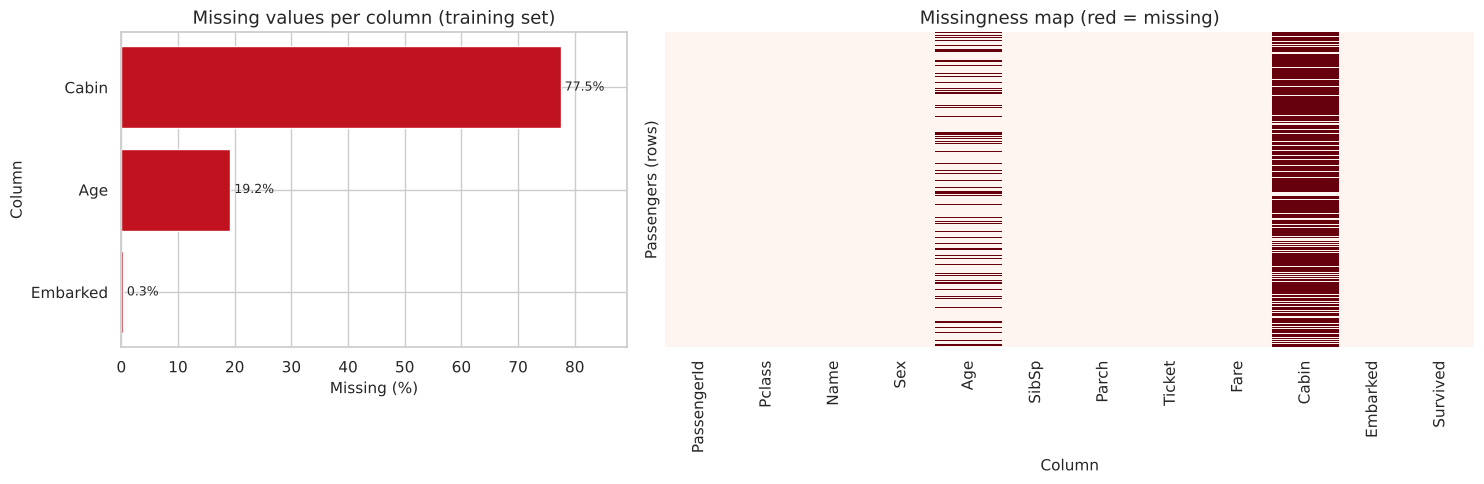

In [9]:
missing = pd.DataFrame({
    "n_missing": train_df.isna().sum(),
    "pct_missing": train_df.isna().mean() * 100,
}).query("n_missing > 0").sort_values("pct_missing", ascending=False)
display(missing)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.6]})
barh(missing["pct_missing"], "Missing values per column (training set)", "Missing (%)", "Column",
     ax=axes[0], color="#c1121f", fmt="{:.1f}%")
sns.heatmap(train_df.isna(), cbar=False, yticklabels=False, cmap="Reds", ax=axes[1])
axes[1].set_title("Missingness map (red = missing)")
axes[1].set_xlabel("Column"); axes[1].set_ylabel("Passengers (rows)")
plt.tight_layout(); plt.show()

**Observations (training set):**
- `Cabin` is missing for **77.5 %** (552 of 712 rows): far too empty to impute, so we turn it into `Deck` with an explicit "unknown" (`U`) category.
- `Age` is missing for **19.2 %** (137 rows): filled with the training median inside the pipeline.
- `Embarked` is missing for only **2 rows** (0.3 %): filled with the most frequent port.
- The map shows that missing `Age` and `Cabin` values are scattered across the file, not clustered in one block of rows.

### 3.2 Target variable distribution

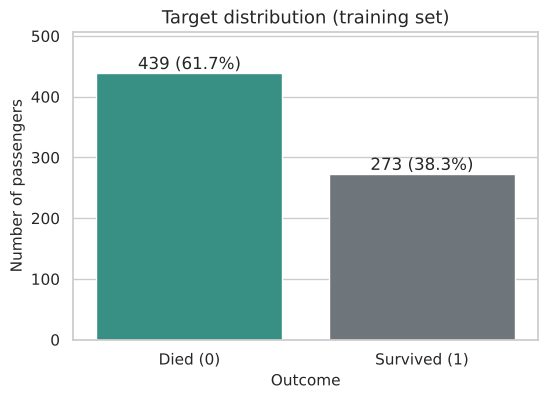

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=y_train.map({0: "Died (0)", 1: "Survived (1)"}), order=["Died (0)", "Survived (1)"], ax=ax, palette=["#6c757d", "#2a9d8f"], hue=y_train.map({0: "Died (0)", 1: "Survived (1)"}), legend=False)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height() / len(y_train):.1%})", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Target distribution (training set)"); ax.set_xlabel("Outcome"); ax.set_ylabel("Number of passengers")
ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
plt.show()

**Observations:** In the training set **61.7 % died and 38.3 % survived**. This is moderately imbalanced (not severe). Two consequences: (1) a model that always says "died" already scores about 61.7 % accuracy, so any real model must be judged against that floor (we do this with a dummy model in Section 8); (2) `stratify=y` was important so that train and test keep the same ratio.

### 3.3 Numerical feature distributions

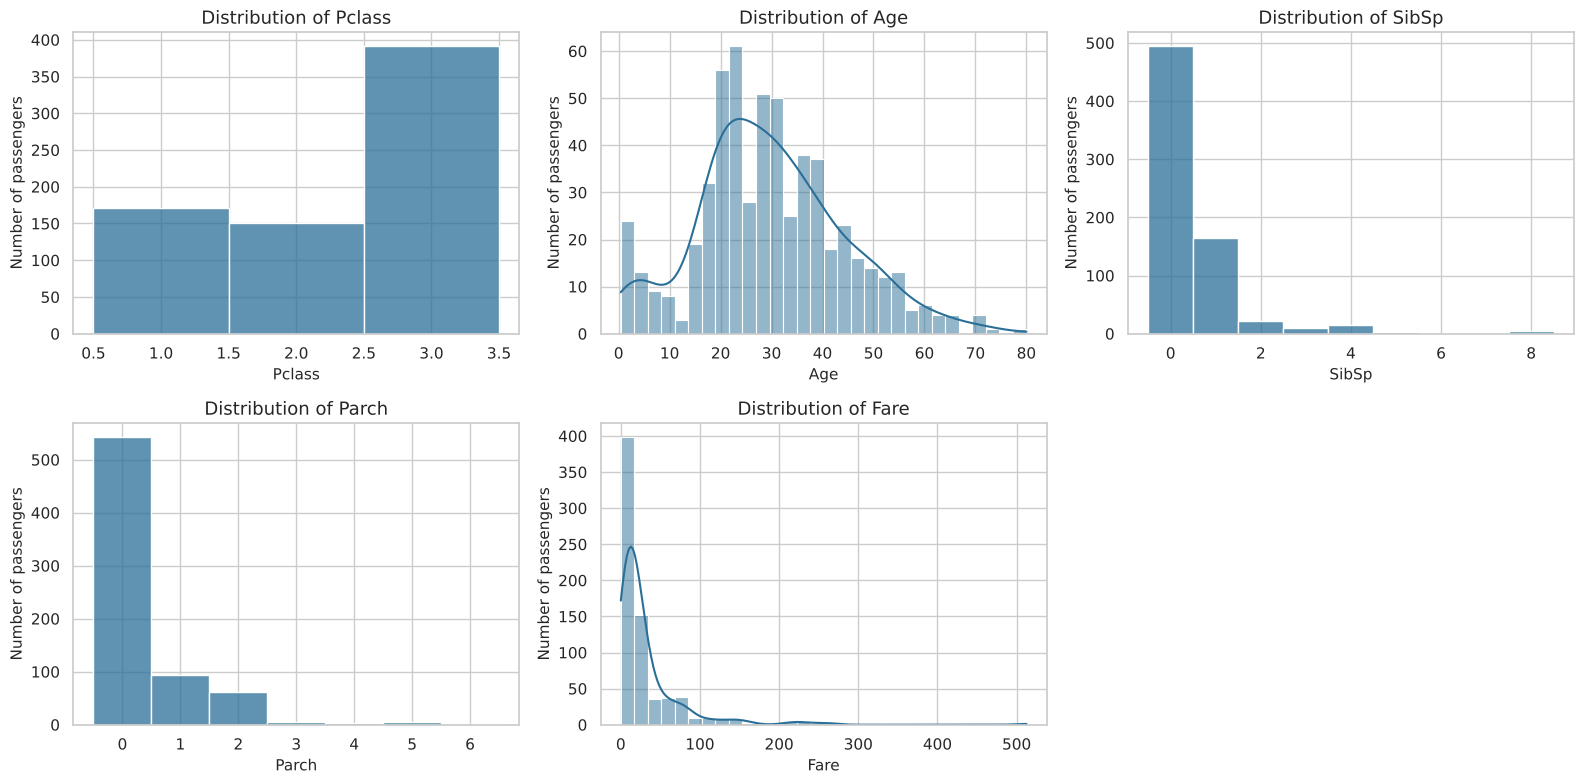

,Pclass,Age,SibSp,Parch,Fare
skewness,-0.6306,0.3533,3.8156,2.8426,4.6462


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8)); axes = axes.ravel()
for ax, col in zip(axes, num_cols_raw):
    continuous = train_df[col].nunique() > 10
    sns.histplot(train_df[col].dropna(), bins=30 if continuous else None, kde=continuous, discrete=not continuous, ax=ax, color="#2a6f97")
    ax.set_title(f"Distribution of {col}"); ax.set_xlabel(col); ax.set_ylabel("Number of passengers")
for ax in axes[len(num_cols_raw):]:
    ax.set_visible(False)
plt.tight_layout(); plt.show()
display(train_df[num_cols_raw].skew().rename("skewness").to_frame().T)

**Observations:** `Fare` (skewness 4.65), `SibSp` (3.82) and `Parch` (2.84) are **strongly right-skewed**: most passengers have small values and a few have very large ones. `Age` is close to symmetric (skewness 0.35), and `Pclass` has the most passengers in class 3. Because of the long tails we clip extreme values (Section 5) before scaling, so a few extreme fares do not dominate the standard deviation.

### 3.4 Categorical feature distributions (and survival rate)

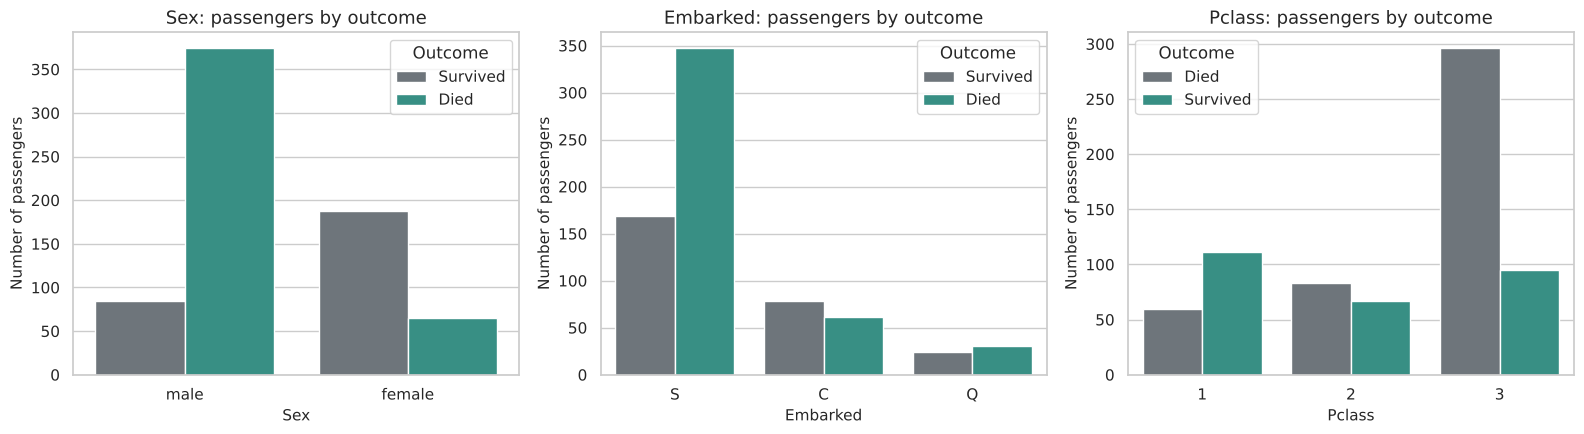

Sex,female,male
n,253.0000,459.0000
survival_rate,0.7430,0.1850


Embarked,C,Q,S
n,139.0000,55.0000,516.0000
survival_rate,0.5610,0.4360,0.3280


Pclass,1,2,3
n,171.0000,150.0000,391.0000
survival_rate,0.6490,0.4470,0.2430


Cardinality of text columns (rows in train = 712 ):


,Name,Ticket,Cabin,Sex,Embarked
n_unique,712,571,127,2,3


In [12]:
categorical_view = ["Sex", "Embarked", "Pclass"]
assert all(c in train_df.columns for c in categorical_view), "Expected columns are missing"
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, categorical_view):
    sns.countplot(data=train_df, x=col, hue=train_df[TARGET_COL].map({0: "Died", 1: "Survived"}), palette=["#6c757d", "#2a9d8f"], ax=ax)
    ax.set_title(f"{col}: passengers by outcome"); ax.set_xlabel(col); ax.set_ylabel("Number of passengers"); ax.legend(title="Outcome")
plt.tight_layout(); plt.show()

for col in categorical_view:
    display(train_df.groupby(col)[TARGET_COL].agg(n="count", survival_rate="mean").round(3).T)
print("Cardinality of text columns (rows in train =", len(train_df), "):")
display(X_train[["Name", "Ticket", "Cabin", "Sex", "Embarked"]].nunique().rename("n_unique").to_frame().T)

**Observations (training set):**
- **Sex** is a very strong signal: survival was **74.3 % for women** (253) vs **18.5 % for men** (459).
- **Pclass:** survival falls with class: **64.9 %** (class 1), **44.7 %** (class 2), **24.3 %** (class 3).
- **Embarked:** Cherbourg 56.1 %, Queenstown 43.6 %, Southampton 32.8 %. The port is probably mixed up with passenger class (we did not test this), so it should not be read as a cause.
- **High cardinality:** `Name` has 712 unique values in 712 rows, `Ticket` 571 and `Cabin` 127. One-hot encoding these would add hundreds of sparse columns, which is why Section 4 reduces or drops them.

### 3.5 Outlier analysis
We use the **IQR rule** (Tukey fences): a value is flagged if it is below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`. Flagged is not the same as *wrong*: a 512-pound first-class fare is real, just rare. So we do **not** delete these rows; we later **clip (winsorise)** extreme values using bounds learned from the training set only.

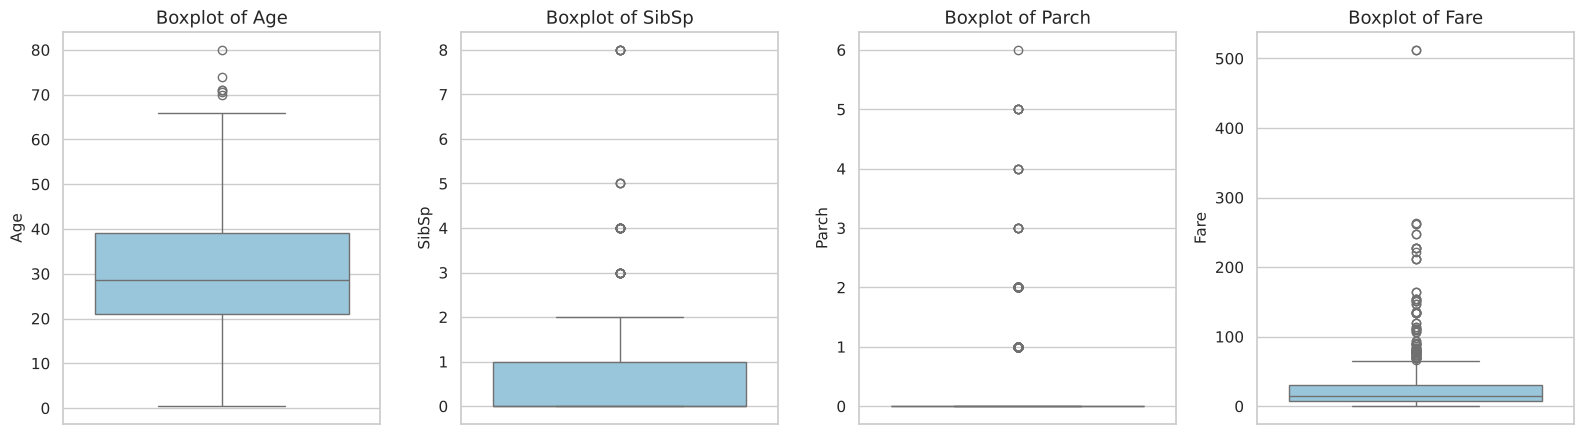

,lower_fence,upper_fence,n_outliers,pct_outliers
feature,,,,
Age,-6.0000,66.0000,6,1.0435
SibSp,-1.5000,2.5000,33,4.6348
Parch,0.0000,0.0000,170,23.8764
Fare,-26.7605,65.6563,91,12.7809


In [13]:
outlier_cols = [c for c in num_cols_raw if c != "Pclass"]
fig, axes = plt.subplots(1, len(outlier_cols), figsize=(16, 4.5))
for ax, col in zip(axes, outlier_cols):
    sns.boxplot(y=train_df[col], ax=ax, color="#8ecae6")
    ax.set_title(f"Boxplot of {col}"); ax.set_ylabel(col); ax.set_xlabel("")
plt.tight_layout(); plt.show()
display(iqr_outlier_report(train_df, outlier_cols))

**Observations (IQR rule, training set):**
- `Fare`: **91 values (12.8 %)** above the upper fence of about 65.7; these are mostly expensive first-class tickets, which are real.
- `SibSp`: 33 values (4.6 %); `Age`: 6 values (1.0 %, above 66 years).
- `Parch`: 170 values (23.9 %) are flagged only because the IQR is 0 (most passengers have 0), so both fences collapse to 0. The IQR rule is too strict for count variables with many zeros; treat this number with caution.
- **Decision:** keep all rows and clip each numeric column to the 1st–99th percentile learned from training data (for example `Fare` is capped at about 227.5 and `Age` at 65, see Section 5).

### 3.6 Correlation heatmap (raw numeric features + target)

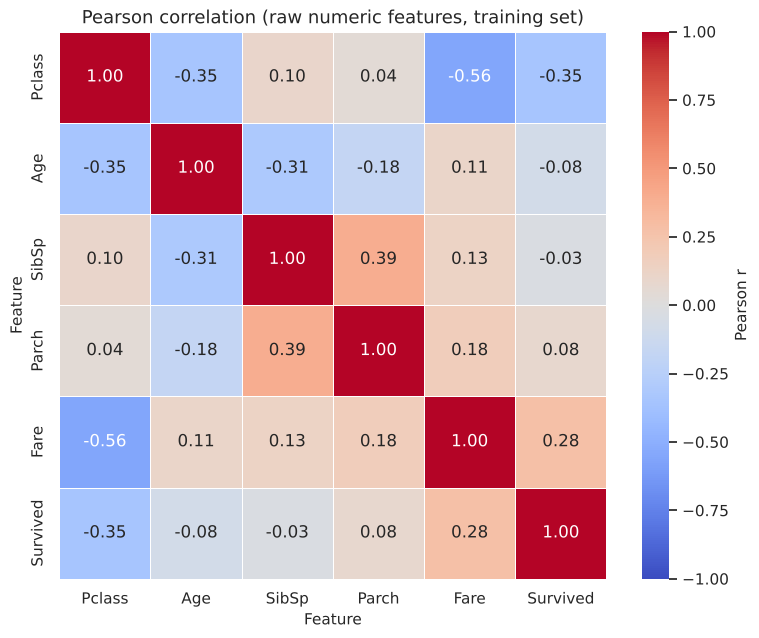

Correlation of each raw numeric feature with Survived:


,Pclass,Fare,Age,Parch,SibSp
pearson_r,-0.3480,0.2755,-0.0843,0.0842,-0.0261


In [14]:
corr_raw = train_df[num_cols_raw + [TARGET_COL]].corr(method="pearson")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr_raw, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax, cbar_kws={"label": "Pearson r"})
ax.set_title("Pearson correlation (raw numeric features, training set)")
ax.set_xlabel("Feature"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.show()
print("Correlation of each raw numeric feature with Survived:")
display(corr_raw[TARGET_COL].drop(TARGET_COL).sort_values(key=abs, ascending=False).rename("pearson_r").to_frame().T)

**Observations:** Linear correlation with `Survived` is strongest for `Pclass` (**−0.35**, higher class number = lower survival) and `Fare` (**+0.28**). `Age` (−0.08), `Parch` (+0.08) and `SibSp` (−0.03) are weak. Weak *linear* correlation does not mean "useless": relationships can be non-linear or depend on other features (see `FamilySize` and `Age` later). `Pclass` and `Fare` are themselves moderately negatively correlated, which is expected because higher classes pay more.

## 4. Feature engineering

Feature engineering means creating new columns that expose useful patterns more clearly to the model. All rules below are **stateless, row-by-row rules** (e.g. `FamilySize = SibSp + Parch + 1`). They learn nothing from the data, so they **cannot leak**. They live in the class `TitanicFeatureEngineer` (a scikit-learn transformer), so they are applied identically to train, test and any future data.

| New feature | How it is built | Why it is useful |
|---|---|---|
| `Title` | Text between the comma and the full stop in `Name` (Mr, Mrs, Miss, Master, other → `Rare`) | Encodes sex, age group and social status in one column; turns 891 unique names into 5 groups |
| `FamilySize` | `SibSp + Parch + 1` | Travelling with family may help or hurt survival; one number is simpler than two |
| `IsAlone` | `1` if `FamilySize == 1` | Lone travellers behave differently from groups |
| `Deck` | First letter of `Cabin`; `U` (unknown) if missing | `Cabin` is 77 % empty, and *having* a cabin is informative; the deck letter is a low-cardinality stand-in for location on the ship |
| `FarePerPerson` | `Fare / FamilySize` | Tickets are shared by groups, so the fare per head is closer to the real price paid |

**Dropped:** `PassengerId` (just a row number), `Name` and `Ticket` (almost unique per passenger → one-hot encoding would create hundreds of useless columns and invite over-fitting), `Cabin` (replaced by `Deck`).

**High-cardinality handling:** instead of one-hot-encoding hundreds of values, we *reduce* them: `Name → Title`, `Cabin → Deck`, `Ticket → dropped`. Any value never seen in training is handled by `OneHotEncoder(handle_unknown="ignore")`.

**Why `Deck = 'U'` and not "most frequent" imputation?** If we let the imputer fill missing cabins with the most common deck, we would wrongly claim that 77 % of passengers sat on that deck. "Unknown" is a real category here.

In [15]:
engineer = TitanicFeatureEngineer()
X_train_fe = engineer.fit_transform(X_train)    # stateless: fit only validates the columns

print("Added  :", sorted(set(X_train_fe.columns) - set(X_train.columns)))
print("Dropped:", sorted(set(X_train.columns) - set(X_train_fe.columns)))
display(pd.concat([X_train[["Name", "SibSp", "Parch", "Cabin", "Fare"]].head(5).reset_index(drop=True),
                   X_train_fe[["Title", "FamilySize", "IsAlone", "Deck", "FarePerPerson"]].head(5).reset_index(drop=True)], axis=1))

Added  : ['Deck', 'FamilySize', 'FarePerPerson', 'IsAlone', 'Title']
Dropped: ['Cabin', 'Name', 'PassengerId', 'Ticket']


,Name,SibSp,Parch,Cabin,Fare,Title,FamilySize,IsAlone,Deck,FarePerPerson
0,"Lam, Mr. Ali",0,0,NaN,56.4958,Mr,1,1,U,56.4958
1,"Frost, Mr. Anthony Wood ""Archie""",0,0,NaN,0.0000,Mr,1,1,U,0.0000
2,"Farthing, Mr. John",0,0,C95,221.7792,Mr,1,1,C,221.7792
3,"Aks, Mrs. Sam (Leah Rosen)",0,1,NaN,9.3500,Mrs,2,0,U,4.6750
4,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",1,1,NaN,26.2500,Mrs,3,0,U,8.7500


**Evidence that the engineered features carry signal** (survival rate per category, training data only):

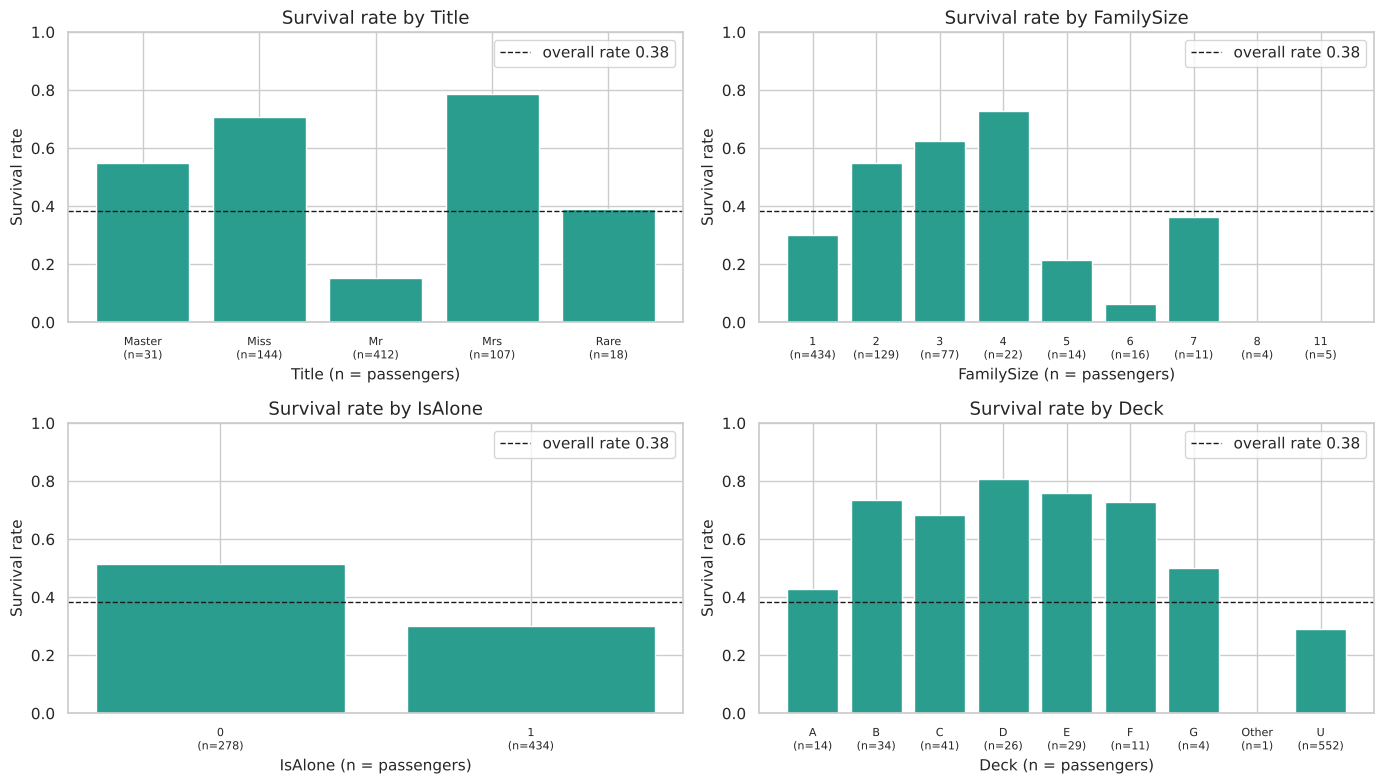

Title,Master,Miss,Mr,Mrs,Rare
n,31.0000,144.0000,412.0000,107.0000,18.0000
survival_rate,0.5480,0.7080,0.1530,0.7850,0.3890


FamilySize,1,2,3,4,5,6,7,8,11
n,434.0000,129.0000,77.0000,22.0000,14.0000,16.0000,11.0000,4.0000,5.0000
survival_rate,0.3000,0.5500,0.6230,0.7270,0.2140,0.0620,0.3640,0.0000,0.0000


IsAlone,0,1
n,278.0000,434.0000
survival_rate,0.5140,0.3000


Deck,A,B,C,D,E,F,G,Other,U
n,14.0000,34.0000,41.0000,26.0000,29.0000,11.0000,4.0000,1.0000,552.0000
survival_rate,0.4290,0.7350,0.6830,0.8080,0.7590,0.7270,0.5000,0.0000,0.2920


In [16]:
fe_train = X_train_fe.assign(**{TARGET_COL: y_train})
fig, axes = plt.subplots(2, 2, figsize=(14, 8)); axes = axes.ravel()
for ax, col in zip(axes, ["Title", "FamilySize", "IsAlone", "Deck"]):
    g = fe_train.groupby(col)[TARGET_COL].agg(["mean", "count"])
    labels = [f"{i}\n(n={n})" for i, n in zip(g.index, g["count"])]
    ax.bar(labels, g["mean"], color="#2a9d8f")
    ax.axhline(y_train.mean(), color="k", ls="--", lw=1, label=f"overall rate {y_train.mean():.2f}")
    ax.set_title(f"Survival rate by {col}"); ax.set_xlabel(f"{col} (n = passengers)"); ax.set_ylabel("Survival rate")
    ax.set_ylim(0, 1); ax.legend(loc="upper right"); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()
for col in ["Title", "FamilySize", "IsAlone", "Deck"]:
    display(fe_train.groupby(col)[TARGET_COL].agg(n="count", survival_rate="mean").round(3).T)

**Observations (training set):**
- **Title** separates passengers well: `Mr` survived **15.3 %** (n = 412) vs `Mrs` **78.5 %**, `Miss` **70.8 %**, `Master` (boys) **54.8 %**. It overlaps with `Sex`, which we examine in Section 7.
- **Deck:** passengers with a known deck B–F had **68–81 %** survival, while `U` (unknown, n = 552) had **29.2 %**. Decks A, G and Other have only 14, 4 and 1 passengers, so their rates are unreliable. `Deck` probably overlaps with passenger class (not tested here).
- **FamilySize** is **not linear**: survival is 30.0 % when travelling alone (n = 434), rises to 72.7 % for a family of 4, then collapses (21.4 % at 5, 6.2 % at 6, 0 % at 8 and 11, but those groups are small). A single "number of relatives" column would hide this pattern.
- **IsAlone:** 30.0 % (alone) vs 51.4 % (with family).

## 5. Preprocessing pipeline (`ColumnTransformer` + `Pipeline`)

```
raw X ──► TitanicFeatureEngineer ──► ColumnTransformer ─┬─ numeric branch:     median imputer → quantile clipper → StandardScaler
                                                        └─ categorical branch: most-frequent imputer → OneHotEncoder(handle_unknown="ignore")
                                                                         ──► model
```

| Step | What it does | Learned from train (`fit`) |
|---|---|---|
| `SimpleImputer(median)` | fills missing numbers | the median of each column |
| `QuantileClipper(1 %, 99 %)` | caps extreme values (outlier handling without deleting rows) | the 1st and 99th percentile of each column |
| `StandardScaler` | rescales to mean 0, std 1 | mean and std of each column |
| `SimpleImputer(most_frequent)` | fills missing categories | the most common value |
| `OneHotEncoder(handle_unknown="ignore")` | one 0/1 column per category | the list of categories; unseen ones become all-zeros instead of crashing |

**Why median and not mean?** The median is not pulled by extreme values (e.g. a 512-pound fare).
**Why clip *before* scaling?** Otherwise a few extreme values would inflate the standard deviation and squash everyone else.
**Why a Pipeline?** `pipeline.fit(X_train, y_train)` guarantees that every step is fitted on training data only, and `pipeline.predict(X_test)` only *applies* what was learned.

Numeric vs categorical columns are chosen **by data type at fit time** (numbers vs everything else), so no column list is hard-coded.

In [17]:
set_config(display="diagram")
baseline_pipe = build_pipeline(
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    feature_engineer=TitanicFeatureEngineer(),
)
baseline_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,drop_family_components,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse

In [18]:
# FIT on training data only
baseline_pipe.fit(X_train, y_train)

# Inspect the fitted preprocessing part; then only TRANSFORM both sets (no refitting).
prep = baseline_pipe[:-1]                                  # feature engineering + ColumnTransformer
preprocessor = baseline_pipe.named_steps["preprocess"]
feature_map = get_feature_map(preprocessor)                # transformed column -> original feature
feature_names = feature_map["transformed_feature"].tolist()

X_train_t = pd.DataFrame(prep.transform(X_train), columns=feature_names, index=X_train.index)
X_test_t = pd.DataFrame(prep.transform(X_test), columns=feature_names, index=X_test.index)

print("Transformed train:", X_train_t.shape, "| transformed test:", X_test_t.shape)
print("Missing values after preprocessing -> train:", int(X_train_t.isna().sum().sum()), "| test:", int(X_test_t.isna().sum().sum()))
display(feature_map)

Transformed train: (712, 27) | transformed test: (179, 27)
Missing values after preprocessing -> train: 0 | test: 0


,transformed_feature,original_feature,kind
0,num__Pclass,Pclass,numeric
1,num__Age,Age,numeric
2,num__SibSp,SibSp,numeric
3,num__Parch,Parch,numeric
4,num__Fare,Fare,numeric
5,num__FamilySize,FamilySize,numeric
6,num__IsAlone,IsAlone,numeric
7,num__FarePerPerson,FarePerPerson,numeric
8,cat__Sex_female,Sex,categorical
9,cat__Sex_male,Sex,categorical


**What did the pipeline learn from the training set?** These numbers were computed from `X_train` only and are simply re-used for the test set.

In [19]:
num_cols_fit = list(preprocessor.transformers_[0][2])
cat_cols_fit = list(preprocessor.transformers_[1][2])
num_branch = preprocessor.named_transformers_["num"]
cat_branch = preprocessor.named_transformers_["cat"]

learned_numeric = pd.DataFrame({
    "median (imputer)": num_branch["imputer"].statistics_,
    "clip low (1%)": num_branch["clipper"].lower_bounds_,
    "clip high (99%)": num_branch["clipper"].upper_bounds_,
    "mean (scaler)": num_branch["scaler"].mean_,
    "std (scaler)": num_branch["scaler"].scale_,
}, index=num_cols_fit)
display(learned_numeric)
print("Most frequent value per categorical column:", dict(zip(cat_cols_fit, cat_branch["imputer"].statistics_)))
print("Categories learned by the encoder:")
for col, cats in zip(cat_cols_fit, cat_branch["encoder"].categories_):
    print(f"  {col:<9}: {list(cats)}")

,median (imputer),clip low (1%),clip high (99%),mean (scaler),std (scaler)
Pclass,3.0000,1.0000,3.0000,2.3090,0.8330
Age,28.5000,1.0000,65.0000,29.4916,12.8042
SibSp,0.0000,0.0000,4.8900,0.4707,0.9268
Parch,0.0000,0.0000,4.0000,0.3806,0.7860
Fare,14.4542,0.0000,227.5250,30.8159,40.9676
FamilySize,1.0000,1.0000,8.0000,1.8624,1.4833
IsAlone,1.0000,0.0000,1.0000,0.6096,0.4879
FarePerPerson,8.4458,0.0000,150.9968,18.9556,25.3668


Most frequent value per categorical column: {'Sex': 'male', 'Embarked': 'S', 'Title': 'Mr', 'Deck': 'U'}
Categories learned by the encoder:
  Sex      : ['female', 'male']
  Embarked : ['C', 'Q', 'S']
  Title    : ['Master', 'Miss', 'Mr', 'Mrs', 'Rare']
  Deck     : ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'Other', 'U']


**Sanity check:** after `StandardScaler` the **training** numeric columns have mean ≈ 0 and std ≈ 1 by construction, while the **test** columns do **not** have exactly mean 0 / std 1. That is the proof that the scaler was *not* re-fitted on test data.

In [20]:
num_t_cols = [c for c in feature_names if c.startswith("num__")]
display(pd.concat({"train": X_train_t[num_t_cols].agg(["mean", "std"]),
                   "test": X_test_t[num_t_cols].agg(["mean", "std"])}, axis=1).T.unstack(0).round(3))

mean            std       
                     train    test  train   test
num__Pclass        -0.0000 -0.0020 1.0010 1.0180
num__Age           -0.0000 -0.0340 1.0010 1.0070
num__SibSp          0.0000  0.1470 1.0010 1.1570
num__Parch         -0.0000 -0.0440 1.0010 0.8450
num__Fare           0.0000  0.0180 1.0010 1.0310
num__FamilySize    -0.0000  0.0630 1.0010 1.0470
num__IsAlone        0.0000 -0.0700 1.0010 1.0160
num__FarePerPerson -0.0000 -0.0740 1.0010 0.7940

**Observations:**
- The pipeline produces **27 columns** (8 numeric + 19 one-hot) from the 11 raw columns, with **0 missing values** in both train and test.
- Learned from training data only: median `Age` = 28.5, median `Fare` = 14.45; the 99th-percentile clip for `Fare` is about 227.5 and for `Age` 65. (`SibSp` shows a clip bound of 4.89 because percentiles are interpolated between values; this is harmless.)
- **Proof of no refitting:** training columns have mean 0 and std ≈ 1 (the 1.001 is a pandas vs scikit-learn standard-deviation convention difference), while test columns do **not** (e.g. `SibSp` test mean 0.147, `Parch` test std 0.845). They were scaled with the training numbers.
- `Pclass` (1–3) is treated as an ordered number; one-hot encoding it would be an alternative design choice.

## 6. Correlation analysis and multicollinearity

**Pearson correlation** `r` measures the *linear* relationship between two numeric variables (−1 to +1).

**Multicollinearity** means two or more *input* features carry (almost) the same information. Effects:
- Linear/logistic models become unstable: coefficients can swing wildly or change sign, and are hard to interpret.
- Tree-based models are mostly unaffected for prediction, but importance gets *split* between the duplicates.
- Duplicated information adds no new knowledge and costs extra computation.

**Variance Inflation Factor (VIF)** quantifies it: `VIF = 1 / (1 − R²)`, where R² comes from predicting one feature using all the others. Rule of thumb: VIF > 5 is a warning, > 10 is serious.

**We will not remove features based on correlation alone.** High correlation is a *reason to test*, so we remove a feature only if cross-validation on the **training** set shows it does not help.

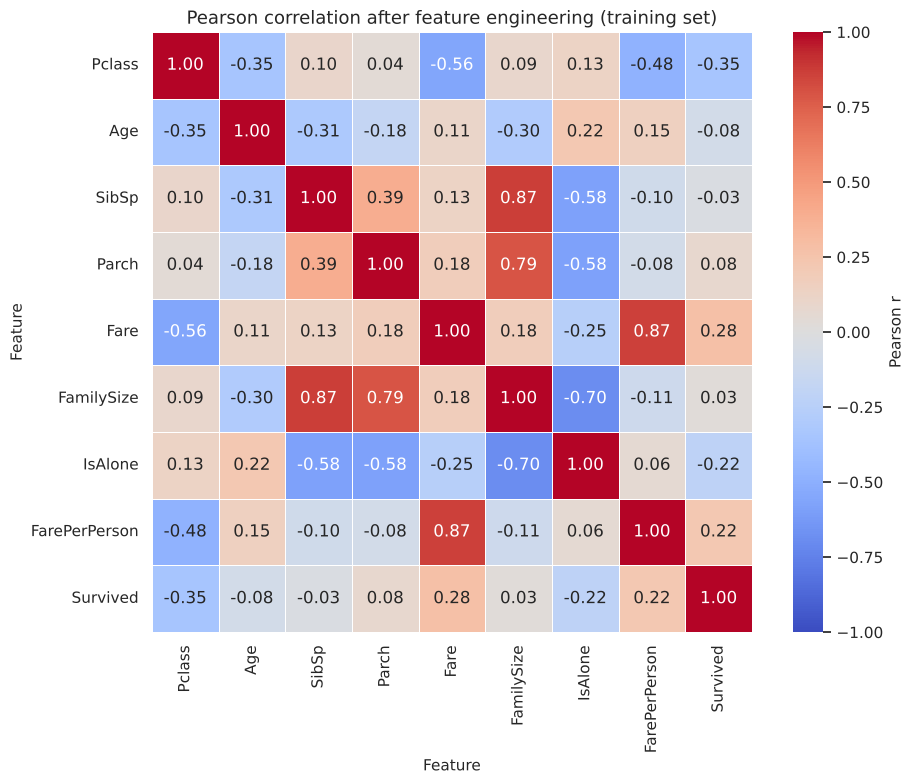

Correlation of each engineered numeric feature with Survived:


,Pclass,Fare,FarePerPerson,IsAlone,Age,Parch,FamilySize,SibSp
pearson_r,-0.3480,0.2755,0.2220,-0.2156,-0.0843,0.0842,0.0270,-0.0261


Feature pairs with |r| >= 0.5:


,feature_1,feature_2,pearson_r
0,SibSp,FamilySize,0.8744
1,Fare,FarePerPerson,0.8669
2,Parch,FamilySize,0.7893
3,FamilySize,IsAlone,-0.6951
4,Parch,IsAlone,-0.5825
5,SibSp,IsAlone,-0.5811
6,Pclass,Fare,-0.5565


In [21]:
numeric_fe_cols = [c for c in fe_train.select_dtypes("number").columns if c != TARGET_COL]
corr_fe = fe_train[numeric_fe_cols + [TARGET_COL]].corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_fe, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax, cbar_kws={"label": "Pearson r"})
ax.set_title("Pearson correlation after feature engineering (training set)")
ax.set_xlabel("Feature"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.show()

# list highly correlated pairs (features only, upper triangle so each pair appears once)
feat_corr = corr_fe.loc[numeric_fe_cols, numeric_fe_cols]
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename("pearson_r").reset_index()
pairs.columns = ["feature_1", "feature_2", "pearson_r"]
print("Correlation of each engineered numeric feature with Survived:")
display(corr_fe[TARGET_COL].drop(TARGET_COL).sort_values(key=abs, ascending=False).rename("pearson_r").to_frame().T)
print("Feature pairs with |r| >= 0.5:")
display(pairs[pairs["pearson_r"].abs() >= 0.5].sort_values("pearson_r", key=abs, ascending=False).reset_index(drop=True))

In [22]:
def compute_vif(frame):
    """VIF of every column of `frame` (all numeric, no missing values)."""
    out = {}
    for col in frame.columns:
        others = frame.drop(columns=col)
        r2 = LinearRegression().fit(others, frame[col]).score(others, frame[col])
        out[col] = np.inf if r2 >= 1 - 1e-12 else 1 / (1 - r2)
    return pd.Series(out, name="VIF").sort_values(ascending=False)

# computed on the already imputed + clipped + scaled TRAINING matrix
vif = compute_vif(X_train_t[num_t_cols]); vif.index = vif.index.str.replace("num__", "")
display(vif.to_frame())

,VIF
FamilySize,228.9361
SibSp,90.9164
Parch,77.2915
Fare,7.1707
FarePerPerson,6.6540
IsAlone,2.6419
Pclass,2.0082
Age,1.2568


**Observations:**
- **Highly correlated pairs:** `SibSp`–`FamilySize` (r = 0.87), `Fare`–`FarePerPerson` (0.87), `Parch`–`FamilySize` (0.79), `FamilySize`–`IsAlone` (−0.70), `Pclass`–`Fare` (−0.56).
- **VIF:** `FamilySize` 229, `SibSp` 91, `Parch` 77 are extreme, as expected because `FamilySize` is *computed from* the other two (clipping makes the match slightly inexact, so it is large rather than infinite). `Fare` (7.2) and `FarePerPerson` (6.7) are in the warning zone; everything else is below 3.
- **Pearson is not enough:** `FamilySize` has almost no linear correlation with survival (r = 0.03), yet Section 4 showed a strong non-linear pattern. Correlation with the target is therefore a poor reason to *drop* a feature.

### 6.1 Testing the removal decision with cross-validation
`FamilySize` is built from `SibSp` and `Parch`, so those three overlap *by construction*. Instead of guessing, we compare **keeping** vs **dropping** `SibSp` and `Parch` using 5-fold CV on the **training set only** (the test set plays no role in this decision), for a linear model and a tree model.

In [23]:
rows = []
for model_name, make_model in {
    "Logistic Regression": lambda: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
}.items():
    for drop in (False, True):
        pipe = build_pipeline(make_model(), TitanicFeatureEngineer(drop_family_components=drop))
        s = cv_summary(pipe, X_train, y_train)
        rows.append({"model": model_name, "SibSp & Parch": "dropped" if drop else "kept",
                     **{f"{m} (mean ± std)": f"{mu:.3f} ± {sd:.3f}" for m, (mu, sd) in s.items()}})
redundancy_cv = pd.DataFrame(rows)
display(redundancy_cv)

,model,SibSp & Parch,accuracy (mean ± std),f1 (mean ± std),roc_auc (mean ± std)
0,Logistic Regression,kept,0.824 ± 0.033,0.770 ± 0.038,0.869 ± 0.020
1,Logistic Regression,dropped,0.824 ± 0.032,0.770 ± 0.034,0.871 ± 0.020
2,Random Forest,kept,0.815 ± 0.015,0.753 ± 0.018,0.876 ± 0.016
3,Random Forest,dropped,0.808 ± 0.016,0.746 ± 0.022,0.875 ± 0.015


**Observations (5-fold CV, training set only):** dropping `SibSp` and `Parch` changes the scores by **0.007 or less** for both models (Logistic Regression accuracy 0.824 → 0.824, ROC-AUC 0.869 → 0.871; Random Forest accuracy 0.815 → 0.808, ROC-AUC 0.876 → 0.875). These differences are much smaller than the fold-to-fold standard deviation (0.015–0.038), so **dropping does not measurably help or hurt**.

**Decision:** keep `SibSp`, `Parch`, `FamilySize` in the default pipeline: there is no evidence that removal improves prediction, and the Random Forest scores very slightly lower without them. If the goal were to *interpret Logistic Regression coefficients*, use `TitanicFeatureEngineer(drop_family_components=True)` to avoid the unstable coefficients that the huge VIFs warn about. `Fare` and `FarePerPerson` (VIF ≈ 7) are kept and flagged; we did not run a separate removal test for them.

## 7. Feature importance analysis

Both methods below are computed on the **training set only**: using test data to rank or select features would be leakage too.

After one-hot encoding, `Sex` becomes `Sex_female` and `Sex_male`, `Title` becomes five columns, and so on. We use `get_feature_map()` to keep track of which transformed column belongs to which original feature, so we can also report importance **per original feature** (by summing its columns).

### 7.1 Mutual Information (MI)
MI measures **how much knowing a feature reduces uncertainty about the target** (0 = independent; larger = more informative). It can capture non-linear relations, looks at **one feature at a time**, and needs no model.

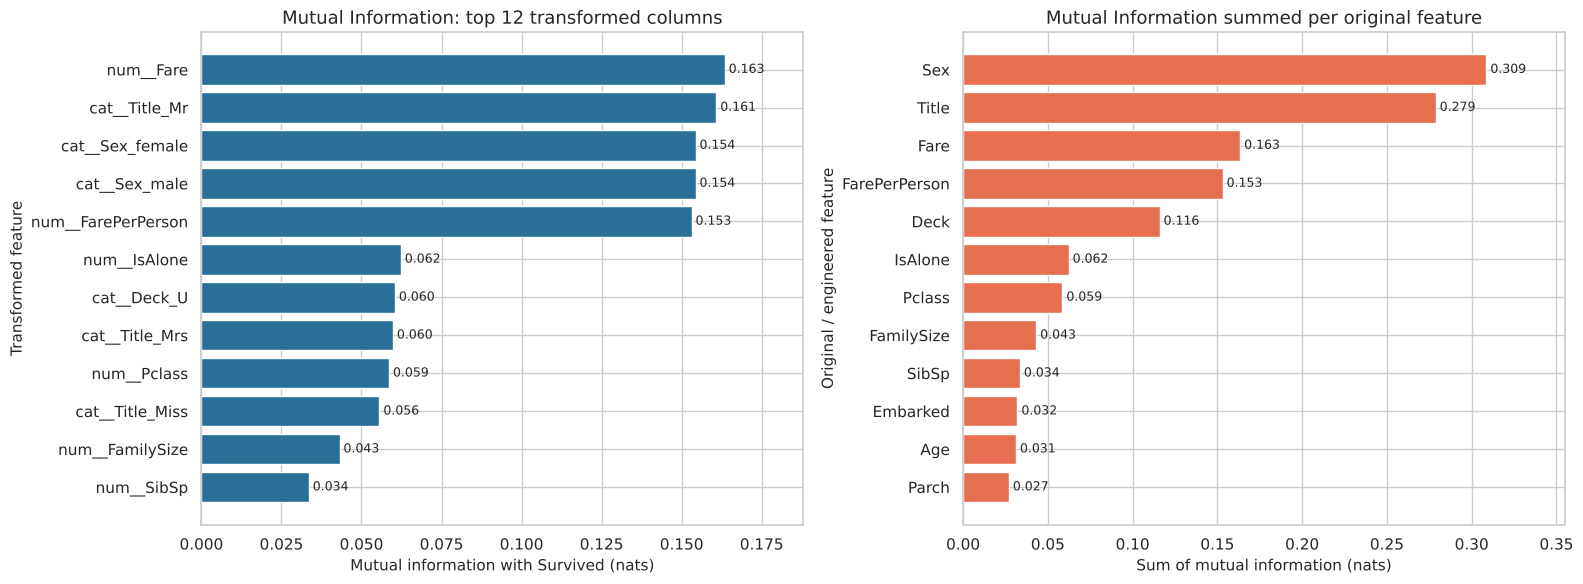

,transformed_feature,original_feature,kind,mutual_info
0,num__Fare,Fare,numeric,0.1635
1,cat__Title_Mr,Title,categorical,0.1608
2,cat__Sex_female,Sex,categorical,0.1543
3,cat__Sex_male,Sex,categorical,0.1543
4,num__FarePerPerson,FarePerPerson,numeric,0.1531
5,num__IsAlone,IsAlone,numeric,0.0623
6,cat__Deck_U,Deck,categorical,0.0605
7,cat__Title_Mrs,Title,categorical,0.0598
8,num__Pclass,Pclass,numeric,0.0586
9,cat__Title_Miss,Title,categorical,0.0556


In [24]:
mi_df = compute_mutual_information(X_train_t.to_numpy(), y_train, feature_map)
mi_by_feature = aggregate_by_original(mi_df, "mutual_info")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
barh(mi_df.set_index("transformed_feature")["mutual_info"].head(12), "Mutual Information: top 12 transformed columns",
     "Mutual information with Survived (nats)", "Transformed feature", ax=axes[0])
barh(mi_by_feature.head(12), "Mutual Information summed per original feature",
     "Sum of mutual information (nats)", "Original / engineered feature", ax=axes[1], color="#e76f51")
plt.tight_layout(); plt.show()
display(mi_df.head(12))

### 7.2 Tree-based importance (Random Forest)
A Random Forest is trained on the data; each feature's importance is the **total reduction in impurity (Gini)** it brings across all splits in all trees, normalised to sum to 1. It looks at features **together inside a model**, captures **interactions**, and depends on the model being a good fit.

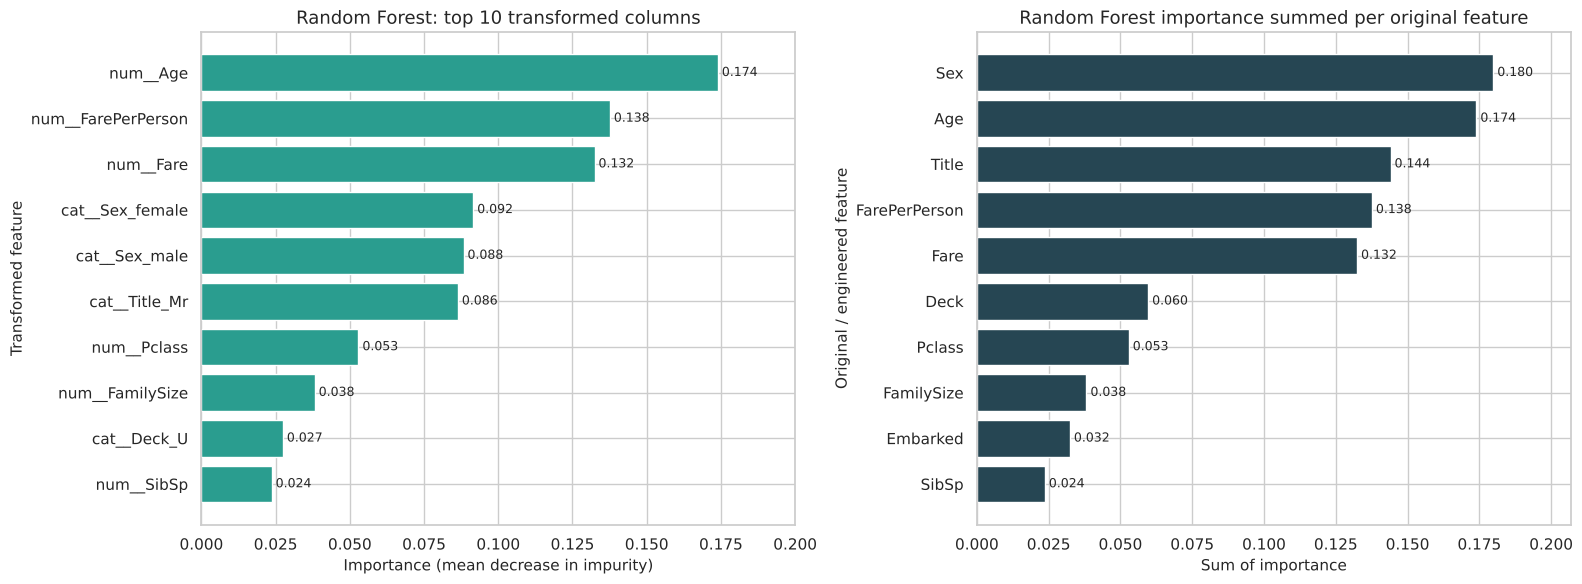

In [25]:
rf_pipe = build_pipeline(
    RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    feature_engineer=TitanicFeatureEngineer(),
)
rf_pipe.fit(X_train, y_train)

rf_map = get_feature_map(rf_pipe.named_steps["preprocess"])
assert rf_map["transformed_feature"].tolist() == feature_names, "feature order must match"
rf_df = rf_map.assign(rf_importance=rf_pipe.named_steps["model"].feature_importances_) \
              .sort_values("rf_importance", ascending=False).reset_index(drop=True)
rf_by_feature = aggregate_by_original(rf_df, "rf_importance")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
barh(rf_df.set_index("transformed_feature")["rf_importance"].head(10), "Random Forest: top 10 transformed columns",
     "Importance (mean decrease in impurity)", "Transformed feature", ax=axes[0], color="#2a9d8f")
barh(rf_by_feature.head(10), "Random Forest importance summed per original feature",
     "Sum of importance", "Original / engineered feature", ax=axes[1], color="#264653")
plt.tight_layout(); plt.show()

In [26]:
comparison = pd.concat([mi_by_feature.rename("MI (sum)"), rf_by_feature.rename("RF importance (sum)")], axis=1)
comparison["MI rank"] = comparison["MI (sum)"].rank(ascending=False).astype(int)
comparison["RF rank"] = comparison["RF importance (sum)"].rank(ascending=False).astype(int)
display(comparison.sort_values("RF rank"))
rho = comparison["MI (sum)"].corr(comparison["RF importance (sum)"], method="spearman")
print(f"Spearman rank correlation between the two rankings: {rho:.2f}")

,MI (sum),RF importance (sum),MI rank,RF rank
original_feature,,,,
Sex,0.3087,0.1799,1,1
Age,0.0312,0.1740,11,2
Title,0.2788,0.1441,2,3
FarePerPerson,0.1531,0.1376,4,4
Fare,0.1635,0.1324,3,5
Deck,0.1159,0.0597,5,6
Pclass,0.0586,0.0529,7,7
FamilySize,0.0431,0.0382,8,8
Embarked,0.0321,0.0324,10,9


Spearman rank correlation between the two rankings: 0.56


### 7.3 Mutual Information vs tree-based importance

| | Mutual Information | Random Forest importance |
|---|---|---|
| Needs a model? | No (model-free, statistical) | Yes (depends on a fitted forest) |
| Looks at | Each feature **alone** vs target | Features **together**, including interactions |
| Relationships | Any (linear or non-linear) | Any, as learned by the trees |
| Redundant features | Both copies get a high score | Importance is **shared/split** between them |
| Known bias | Needs care with continuous estimation | Favours continuous / high-cardinality columns |
| Best used for | Quick screening before modelling | Understanding what a trained model relies on |

A feature can rank high in MI but lower in RF importance if another feature already provides the same information (e.g. `Sex` and `Title`).

**Observations (training set only):**
- **MI top columns:** `Fare` 0.164, `Title_Mr` 0.161, `Sex_female` and `Sex_male` 0.154 each, `FarePerPerson` 0.153. The two `Sex` columns have identical MI because one is the exact mirror of the other.
- **Caution on the per-feature sums:** adding the MI of one-hot columns double-counts binary features such as `Sex` (its true MI is about 0.154, not 0.309), so the MI "sum per feature" is only a rough ordering aid. The Random Forest sums are exact because the importances partition the total impurity decrease.
- **Where the methods agree:** `Sex`, `Title`, `FarePerPerson` and `Fare` are in the top 5 of both; `Embarked`, `SibSp` and `Parch` are near the bottom of both.
- **Where they disagree:** `Age` is **rank 2 for Random Forest (0.174) but rank 11 for MI (0.031)**. This is consistent with the known tendency of impurity-based importance to favour continuous columns that offer many split points (we did not run permutation importance to confirm). `IsAlone` is rank 6 in MI but rank 12 in RF: its information is already contained in `FamilySize`, `SibSp` and `Parch`, so the forest gives it little extra credit.
- The Spearman rank correlation between the two rankings is **0.56**: partial agreement, so using two methods was worthwhile.
- `Sex`, `Title` and `Pclass` overlap in what they encode, so their individual scores should not be added up as if they were independent.

## 8. Machine-learning pipeline: baseline model and evaluation

The baseline is **Logistic Regression** inside the full pipeline (`feature engineering → preprocessing → model`). To judge whether it is any good we compare with:
- a **dummy model** that always predicts the majority class (the "do-nothing" floor), and
- a **Random Forest** (a more flexible model).

**Metrics (binary classification):**
- **Accuracy** = share of correct predictions.
- **Precision** = of those predicted "survived", how many really survived.
- **Recall** = of all who really survived, how many we found.
- **F1** = harmonic mean of precision and recall.
- **ROC-AUC** = ability to rank survivors above non-survivors (0.5 = random, 1.0 = perfect).
- **Confusion matrix** = counts of true/false positives/negatives.

In [27]:
dummy_pipe = build_pipeline(DummyClassifier(strategy="most_frequent"), TitanicFeatureEngineer()).fit(X_train, y_train)
models = {"Dummy (majority class)": dummy_pipe,
          "Logistic Regression (baseline)": baseline_pipe,
          "Random Forest": rf_pipe}

results = {name: evaluate_classifier(m, X_test, y_test) for name, m in models.items()}
test_table = pd.DataFrame({n: {k: v for k, v in r["metrics"].items() if k != "confusion_matrix"} for n, r in results.items()}).T
print("Hold-out TEST metrics (the test set is used for evaluation only):")
display(test_table)

train_metrics = evaluate_classifier(baseline_pipe, X_train, y_train)["metrics"]
print("Baseline accuracy on TRAIN vs TEST:", round(train_metrics["accuracy"], 3), "vs", round(results["Logistic Regression (baseline)"]["metrics"]["accuracy"], 3))
p, n = results["Logistic Regression (baseline)"]["metrics"]["accuracy"], len(y_test)
print(f"Rough uncertainty of the test accuracy with n={n}: +/- {1.96 * np.sqrt(p * (1 - p) / n):.3f} (95% interval)")

Hold-out TEST metrics (the test set is used for evaluation only):


,accuracy,precision,recall,f1,roc_auc
Dummy (majority class),0.6145,0.0000,0.0000,0.0000,0.5000
Logistic Regression (baseline),0.8492,0.8281,0.7681,0.7970,0.8700
Random Forest,0.8045,0.7576,0.7246,0.7407,0.8359


Baseline accuracy on TRAIN vs TEST: 0.834 vs 0.849
Rough uncertainty of the test accuracy with n=179: +/- 0.052 (95% interval)


              precision    recall  f1-score   support

        Died       0.86      0.90      0.88       110
    Survived       0.83      0.77      0.80        69

    accuracy                           0.85       179
   macro avg       0.84      0.83      0.84       179
weighted avg       0.85      0.85      0.85       179



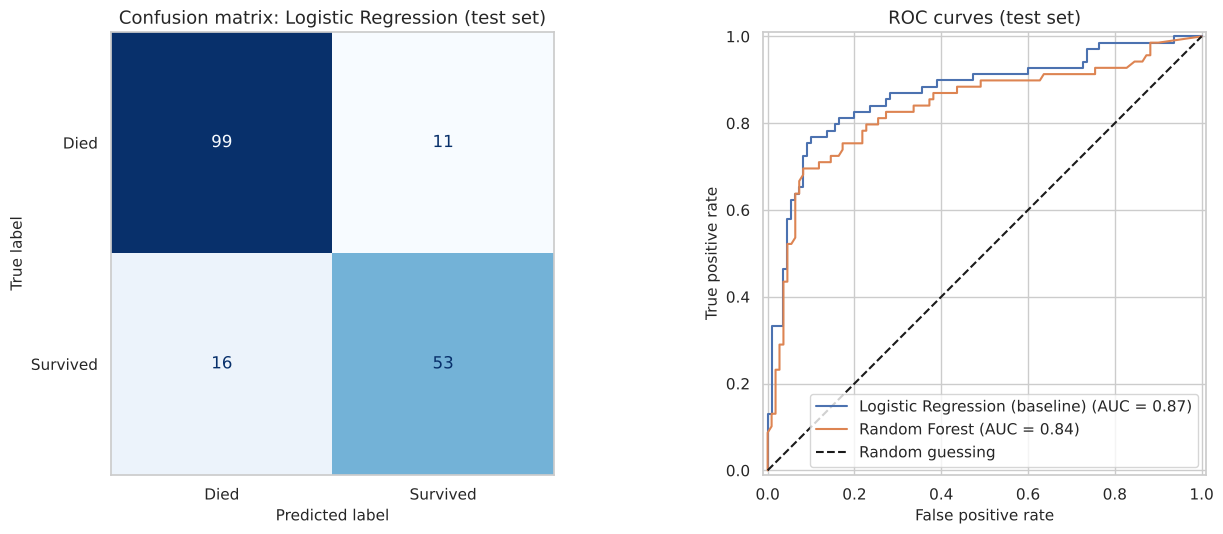

In [28]:
base = results["Logistic Regression (baseline)"]
print(classification_report(y_test, base["y_pred"], target_names=["Died", "Survived"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, base["y_pred"], display_labels=["Died", "Survived"], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix: Logistic Regression (test set)")
axes[0].set_xlabel("Predicted label"); axes[0].set_ylabel("True label"); axes[0].grid(False)

for name in ["Logistic Regression (baseline)", "Random Forest"]:
    RocCurveDisplay.from_predictions(y_test, results[name]["y_proba"], name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guessing")
axes[1].set_title("ROC curves (test set)"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

**Cross-validation on the training set** (more stable than one 179-row test set; the whole pipeline is re-fitted in every fold):

In [29]:
cv_rows = {}
for name, m in {"Dummy (majority class)": build_pipeline(DummyClassifier(strategy="most_frequent"), TitanicFeatureEngineer()),
                "Logistic Regression (baseline)": build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), TitanicFeatureEngineer()),
                "Random Forest": build_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), TitanicFeatureEngineer())}.items():
    s = cv_summary(m, X_train, y_train)
    cv_rows[name] = {f"{k} (mean ± std)": f"{mu:.3f} ± {sd:.3f}" for k, (mu, sd) in s.items()}
display(pd.DataFrame(cv_rows).T)

,accuracy (mean ± std),f1 (mean ± std),roc_auc (mean ± std)
Dummy (majority class),0.617 ± 0.003,0.000 ± 0.000,0.500 ± 0.000
Logistic Regression (baseline),0.824 ± 0.033,0.770 ± 0.038,0.869 ± 0.020
Random Forest,0.813 ± 0.015,0.753 ± 0.017,0.874 ± 0.015


**Observations:**
- **Baseline (Logistic Regression), test set:** accuracy **0.849**, precision 0.828, recall 0.768, F1 0.797, ROC-AUC 0.870. The confusion matrix shows 99 correctly predicted deaths, 11 false alarms, 16 missed survivors and 53 correctly predicted survivors. It misses about 23 % of real survivors (recall 0.77).
- **Not over-fitted:** training accuracy 0.834 vs test accuracy 0.849. The test score is slightly higher by chance; with only 179 test rows the 95 % uncertainty is about ±5 points.
- **Floor:** the dummy model scores 0.615 accuracy and 0.50 ROC-AUC, so the pipeline clearly learns real signal.
- **Logistic Regression vs Random Forest:** on the test set LR is better (accuracy 0.849 vs 0.805), but in cross-validation they are close (accuracy 0.824 ± 0.033 vs 0.813 ± 0.015; ROC-AUC 0.869 vs 0.874). The differences are within noise, so we do **not** claim a winner; the simpler Logistic Regression is a sound, explainable baseline.
- No hyper-parameter tuning or threshold tuning was done; this is a baseline by design.

## 9. Final validation (automated checks)

Every check below is an `assert`: if something were wrong the notebook would stop with an error instead of silently continuing.

In [30]:
checks = []
def check(name, condition):
    assert condition, f"FAILED: {name}"
    checks.append(name); print(f"[PASS] {name}")

# 1. Split happened before fitting, no overlap, stratification preserved
check("Train and test indices do not overlap", set(X_train.index).isdisjoint(X_test.index))
check("Train + test = all rows", len(X_train) + len(X_test) == len(X))
check("Class proportions equal in train and test (|diff| < 1 pt)", abs(y_train.mean() - y_test.mean()) < 0.01)

# 2. Preprocessing statistics were learned from TRAIN only
train_medians = X_train_fe[num_cols_fit].median().to_numpy()
check("Imputer medians == medians of X_train", np.allclose(num_branch["imputer"].statistics_, train_medians))
full_medians = engineer.transform(X)[num_cols_fit].median().to_numpy()
print("       (info) medians differ from full-data medians in", int((~np.isclose(train_medians, full_medians)).sum()), "column(s) -> train-only is really used")
check("Test columns are NOT exactly re-centred (scaler was not re-fitted on test)",
      not np.allclose(X_test_t[num_t_cols].mean().to_numpy(), 0, atol=1e-9))

# 3. No missing values after preprocessing
check("No NaN in transformed train", not X_train_t.isna().any().any())
check("No NaN in transformed test", not X_test_t.isna().any().any())
check("All values finite", np.isfinite(X_train_t.to_numpy()).all() and np.isfinite(X_test_t.to_numpy()).all())

# 4. Unseen categories are handled (new Embarked port, new Sex label)
X_unseen = X_test.head(5).copy()
X_unseen["Embarked"] = "Z"           # port never seen in training
X_unseen["Sex"] = "unknown"          # label never seen in training
unseen_t = pd.DataFrame(prep.transform(X_unseen), columns=feature_names)
check("Unseen categories do not crash the pipeline", unseen_t.shape == (5, len(feature_names)))
check("Unseen categories become all-zero one-hot columns",
      (unseen_t.filter(regex=r"^cat__(Embarked|Sex)_") == 0).all().all())
check("End-to-end prediction works on unseen categories", len(baseline_pipe.predict(X_unseen)) == 5)

# 5. Feature names
check("Feature names count == transformed columns", len(feature_names) == X_train_t.shape[1])
check("Feature names are unique", len(set(feature_names)) == len(feature_names))
check("Feature names identical for train and test", list(X_train_t.columns) == list(X_test_t.columns))
check("Every one-hot column maps back to an original feature", feature_map["original_feature"].notna().all())
check("Column lists used by ColumnTransformer = dtype-based lists",
      set(num_cols_fit) == set(X_train_fe.select_dtypes("number").columns) and set(cat_cols_fit) == set(X_train_fe.select_dtypes(exclude="number").columns))

# 6. Feature importance used training data only
check("MI and RF importance computed on training rows only", X_train_t.shape[0] == len(X_train))
check("MI rows == RF rows == number of transformed features", len(mi_df) == len(rf_df) == len(feature_names))

# 7. Reproducibility: refitting a clone gives identical predictions
from sklearn.base import clone
clone_pipe = clone(baseline_pipe).fit(X_train, y_train)
check("Re-fitting a clone with random_state=42 reproduces the predictions", (clone_pipe.predict(X_test) == baseline_pipe.predict(X_test)).all())

print(f"\nAll {len(checks)} checks passed.")

[PASS] Train and test indices do not overlap
[PASS] Train + test = all rows
[PASS] Class proportions equal in train and test (|diff| < 1 pt)
[PASS] Imputer medians == medians of X_train
       (info) medians differ from full-data medians in 2 column(s) -> train-only is really used
[PASS] Test columns are NOT exactly re-centred (scaler was not re-fitted on test)
[PASS] No NaN in transformed train
[PASS] No NaN in transformed test
[PASS] All values finite
[PASS] Unseen categories do not crash the pipeline
[PASS] Unseen categories become all-zero one-hot columns
[PASS] End-to-end prediction works on unseen categories
[PASS] Feature names count == transformed columns
[PASS] Feature names are unique
[PASS] Feature names identical for train and test
[PASS] Every one-hot column maps back to an original feature
[PASS] Column lists used by ColumnTransformer = dtype-based lists
[PASS] MI and RF importance computed on training rows only
[PASS] MI rows == RF rows == number of transformed features


## 10. Reusability demo on the uploaded `customer-churn-training.csv`

The pipeline code is not tied to Titanic: `build_pipeline()` and `build_preprocessor()` choose numeric vs categorical columns by data type. Here we run the **same code** (without the Titanic-specific `TitanicFeatureEngineer`) on the small churn file you uploaded.

**Important caveat:** this file has only **12 rows** (5 churned, 7 not) and **no missing values**. Metrics on a 3-row test set would be meaningless, so we deliberately report **no model score**. This demo only shows that the preprocessing runs, produces the right columns, and handles an unseen plan type.

In [31]:
churn = pd.read_csv("data/customer-churn-training.csv")
print("Shape:", churn.shape, "| missing values:", int(churn.isna().sum().sum()), "| churn counts:", churn["churned"].value_counts().to_dict())

assert churn["customer_id"].is_unique            # validated before dropping: it is only an identifier
Xc, yc = churn.drop(columns=["customer_id", "churned"]), churn["churned"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, random_state=RANDOM_STATE, stratify=yc)

churn_pipe = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))   # no feature_engineer
churn_pipe.fit(Xc_train, yc_train)
churn_map = get_feature_map(churn_pipe.named_steps["preprocess"])
display(churn_map)

Xc_new = Xc_test.copy(); Xc_new["plan_type"] = "Premium"       # a plan never seen in training
out = churn_pipe[:-1].transform(Xc_new)
print("Transformed test shape:", out.shape, "| unseen plan_type -> all-zero one-hot:", bool((out[:, churn_map["transformed_feature"].str.startswith("cat__plan_type")] == 0).all()))

Shape: (12, 7) | missing values: 0 | churn counts: {0: 7, 1: 5}


,transformed_feature,original_feature,kind
0,num__tenure_months,tenure_months,numeric
1,num__support_tickets,support_tickets,numeric
2,num__monthly_spend_inr,monthly_spend_inr,numeric
3,num__last_login_days,last_login_days,numeric
4,cat__plan_type_Basic,plan_type,categorical
5,cat__plan_type_Pro,plan_type,categorical
6,cat__plan_type_Standard,plan_type,categorical


Transformed test shape: (3, 7) | unseen plan_type -> all-zero one-hot: True


**Observations:** the same `build_pipeline()` code handled a completely different dataset: 4 numeric + 1 categorical column became 7 model-ready columns, and an unseen `plan_type = "Premium"` produced all-zero one-hot values instead of an error. No accuracy is reported on purpose: with 12 rows (3 in the test split) any score would be meaningless.

## 11. Summary, limitations and viva Q&A

### Key findings
1. **Leak-free by design:** split first (`random_state=42`, stratified), every learned step lives inside one `Pipeline`, and 19 automated checks in Section 9 passed in the executed run.
2. **Data issues:** `Cabin` 77.5 % missing, `Age` 19.2 % missing, strongly skewed `Fare`/`SibSp`/`Parch`. Handled by `Deck` with an "unknown" category, median imputation, and train-learned percentile clipping.
3. **Feature engineering paid off in the analysis:** `Title`, `Deck`, `FamilySize` and `IsAlone` all show clear survival differences, and `FamilySize` has a non-linear pattern that Pearson correlation missed.
4. **Multicollinearity** (VIF up to 229) comes from features built from each other; a cross-validated test showed removing them changes scores by ≤ 0.007, so they were kept (with a switch to drop them for interpretation).
5. **Most informative features:** `Sex`, `Title`, `Fare`/`FarePerPerson`, and (for the forest) `Age`.
6. **Baseline model:** Logistic Regression, test accuracy 0.849 / ROC-AUC 0.870 (dummy: 0.615 / 0.50).

### Limitations (be ready to state these in the viva)
- Only 891 rows: the test set has 179 rows, so metrics carry about ±5 points of uncertainty.
- Titanic is a historical, small, "toy" dataset. Results say little about modern data.
- Features such as `Sex` and `Pclass` drive the prediction; using such attributes to make decisions about real people would need an ethics/fairness review.
- No hyper-parameter tuning, no probability calibration, no threshold tuning.
- The code was executed here with scikit-learn 1.9.1, pandas 3.0.6, numpy 2.5.4 and matplotlib 3.11.2; the lower bounds in `requirements.txt` reflect the features used and were not separately tested.

### Likely viva questions (with short answers)

**1. What is data leakage and how did you prevent it?**
Leakage is when test-set information influences training or preprocessing. I split first (`random_state=42`, stratified), put every learned step (imputer, clipper, scaler, encoder) inside a `Pipeline`, called `fit` on `X_train` only, and only `transform`/`predict` on `X_test`. Cross-validation also re-fits the whole pipeline inside each fold.

**2. Why median imputation and why `handle_unknown="ignore"`?**
The median is robust to outliers such as very high fares. `handle_unknown="ignore"` makes unseen categories become all-zero rows instead of raising an error in production.

**3. Why didn't you simply delete outliers?**
They are real passengers (e.g. expensive first-class tickets). Deleting rows loses information and would have to be repeated on test data. Clipping with train-learned bounds keeps all rows.

**4. What is multicollinearity and did you remove features?**
Two inputs carrying nearly the same information, which destabilises linear-model coefficients. `FamilySize` is built from `SibSp` + `Parch`, so they overlap by construction. I did not remove them blindly; I tested keep vs drop with cross-validation on the training set (Section 6.1) and decided from those numbers.

**5. Difference between Mutual Information and Random Forest importance?**
MI: model-free, one feature at a time. RF importance: from a fitted model, features compete and share credit, and it can capture interactions (table in Section 7.3).

**6. Why is accuracy alone not enough?**
It hides the kind of mistakes (false positives vs false negatives) and is misleading on imbalanced data; hence precision, recall, F1, ROC-AUC and the confusion matrix.

**7. How do you know the notebook has no leakage?**
Section 9 asserts, among other things, that the imputer medians equal the training medians, that the test set's scaled mean is *not* exactly zero (so the scaler was not re-fitted on it), and that unseen categories are handled.